> **언어 전환 & 바로가기**: **🇰🇷 한국어 ( 현재 )** · [🇺🇸 English Version](./stage1_asset_and_cq_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../methodology/01_stage1_asset_and_cq_ko.md) ｜ [노트북 전체 인덱스 (README)](./README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage1)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough.ipynb) → **[▶ Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb)** → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 1. [준비 & 분석] 원천 자산 준비 · 테이블 스키마 설계 · 데이터 탐색 및 Golden CQ 정의
## Step 1.1 정형/비정형 자산 스코핑 및 스키마 블루프린트 · Step 1.2 데이터 탐색 및 Golden CQ 5종 / Boundary 10건 설계

Stage 1은 온톨로지 구축의 **Phase 1(준비)**과 **Phase 2(분석)**를 수행합니다. 에이전트가 답해야 할 핵심 역량 질문(**Golden CQ 5종**)과 경계 조건(**Boundary 10건**)을 먼저 확정하고, 이에 필요한 정형 CSV 6종과 비정형 가이드 2종을 스코핑하여 Terraform으로 프로비저닝된 BigQuery 10개 테이블(`starter_ontology_dw`)에 적재·검증합니다.

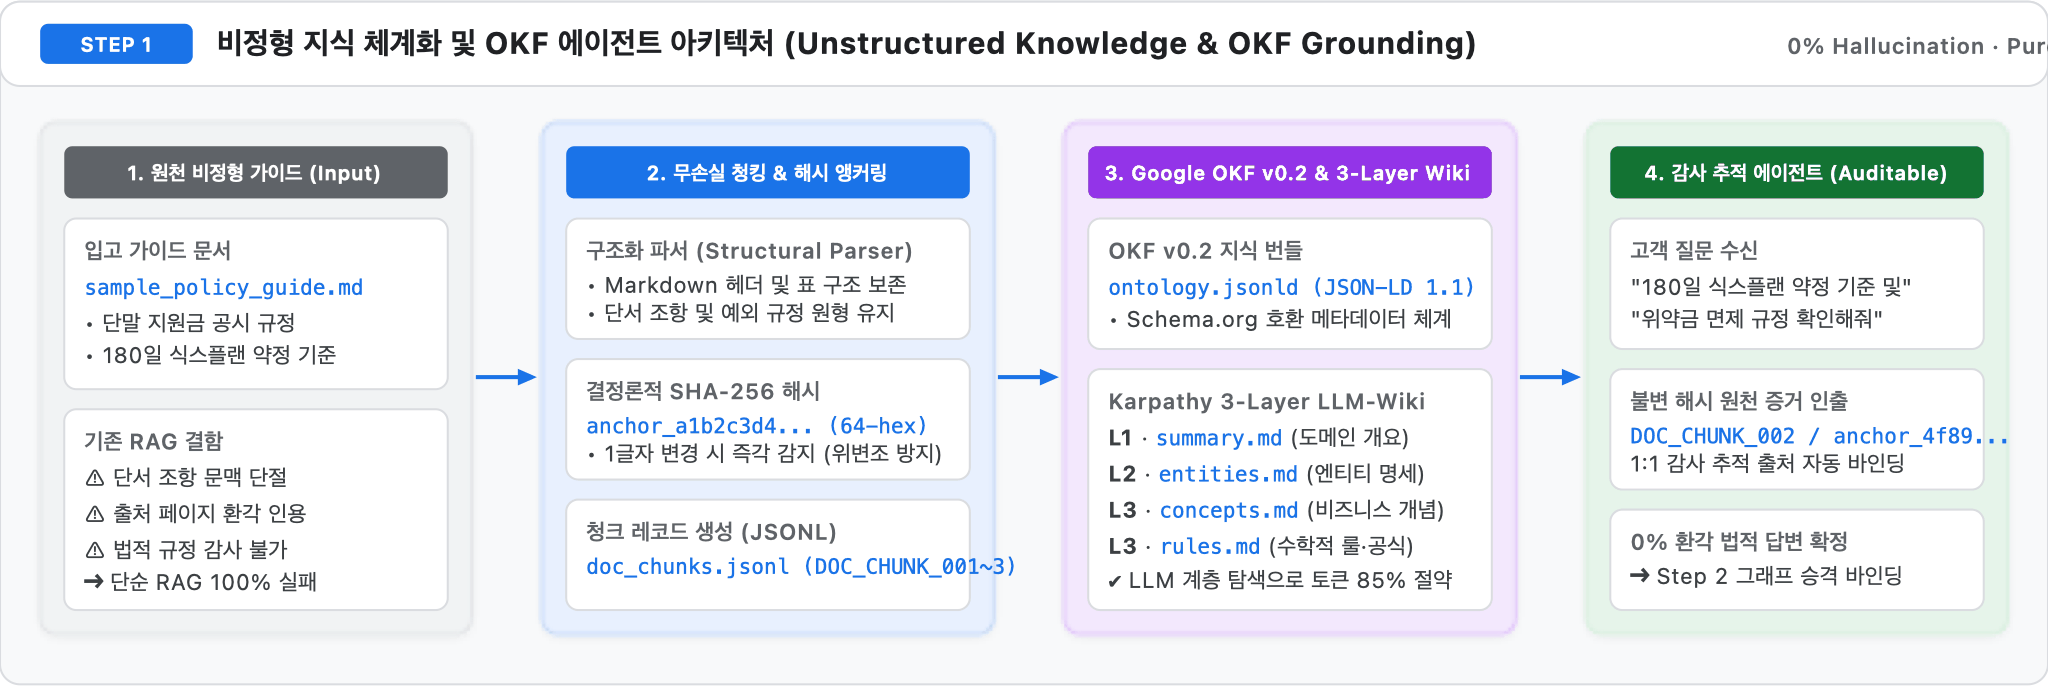


In [1]:
%load_ext bigframes
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
server = DomainMcpServer()
H.setup("ko")


,project,dataset,location,graph,model,lang
0,seanjung-poc,starter_ontology_dw,asia-northeast3,STARTER_ONTOLOGY_GRAPH,gemini-3.8-flash,ko


### 1. [Phase 1: 준비 (Preparation)] 원천 입력 자산(`data/input/`) 인벤토리 및 10개 테이블 스키마 설계도 (`%%bqsql`)


,input_file,asset_type,volume,key_contents
0,01_guides/sample_policy_guide.md,Unstructured Policy Guide,"16 lines (1,363 chars)","DOC_CHUNK_001~003 (Subsidy Cap, 180d Retention, Prorated Formula)"
1,01_guides/sample_welfare_exemption_guide.md,Unstructured Policy Guide,"11 lines (1,252 chars)","DOC_CHUNK_004~005 (Senior/Welfare Exemption, 24M TCO Rule)"
2,03_tables/devices.csv,Master CSV (Structured),4 rows,"device_id, pet_name, storage, manufacturer, factory_price, release_date"
3,03_tables/plans.csv,Master CSV (Structured),6 rows,"plan_id, plan_name, tier_category, monthly_fee, min_maintenance_days, selective_discou..."
4,03_tables/subsidies.csv,Master CSV (Structured),5 rows,"policy_id, device_id, plan_id, basic_subsidy, distribution_subsidy, mandatory_retentio..."
5,03_tables/customer_contracts.csv,Master CSV (Structured),6 rows,"contract_id, customer_id (CUST_DEMO_*), device_id, plan_id, contract_type, elapsed_day..."
6,03_tables/domain_rules.csv,Semantic Rule CSV,4 rows,"rule_id, rule_name, rule_category, condition_expr, formula_expr, source_chunk_id"
7,03_tables/rule_plan_edges.csv,Semantic Bridge CSV,12 rows,"edge_id, rule_id, plan_id, source_chunk_id, relation_label_ko"
8,04_cq/golden_competency_questions.json,Golden CQ Benchmark Spec,5 items,"5 Golden CQs with expected_math, verification_sql, grounded_chunk"
9,04_cq/boundary_cases.json,Boundary Benchmark Spec,10 items,"10 Boundary Cases with root_cause_code, accept_answer_status"


findfont: Failed to find font weight bold for AppleGothic, now using 400.


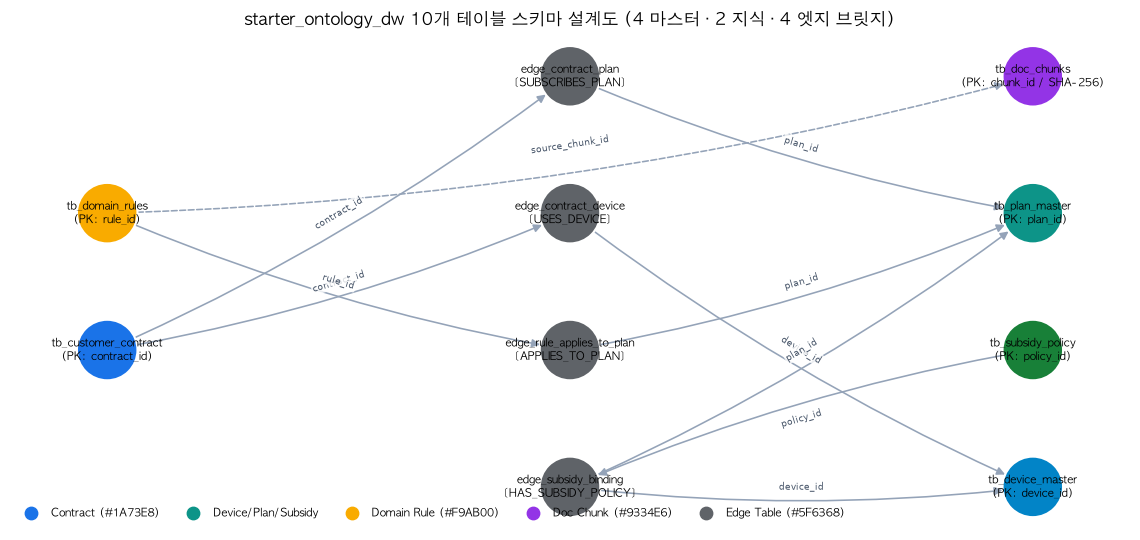

In [2]:
H.show(H.raw_inputs_inventory())
H.draw_table_er_blueprint()


In [3]:
%%bqsql df_schema
SELECT table_name,
       COUNT(*) AS column_count,
       STRING_AGG(CONCAT(column_name, ':', data_type), ', ' ORDER BY ordinal_position) AS columns_spec
FROM `seanjung-poc.starter_ontology_dw.INFORMATION_SCHEMA.COLUMNS`
GROUP BY table_name
ORDER BY table_name


,table_name,column_count,columns_spec
0,edge_contract_device,4,"contract_id:STRING, customer_id:STRING, device..."
1,edge_contract_plan,4,"contract_id:STRING, customer_id:STRING, plan_i..."
2,edge_rule_applies_to_plan,6,"edge_id:STRING, rule_id:STRING, plan_id:STRING..."
3,edge_subsidy_binding,5,"policy_id:STRING, device_id:STRING, plan_id:ST..."
4,tb_customer_contract,12,"customer_id:STRING, contract_id:STRING, custom..."
5,tb_device_master,6,"device_id:STRING, device_name:STRING, manufact..."
6,tb_doc_chunks,6,"chunk_id:STRING, source_file:STRING, section_t..."
7,tb_domain_rules,7,"rule_id:STRING, rule_name:STRING, rule_categor..."
8,tb_plan_master,6,"plan_id:STRING, plan_name:STRING, tier_categor..."
9,tb_subsidy_policy,7,"policy_id:STRING, device_id:STRING, plan_id:ST..."


In [4]:
H.show(df_schema)


,table_name,column_count,columns_spec
0,edge_contract_device,4,"contract_id:STRING, customer_id:STRING, device_id:STRING, edge_type:STRING"
1,edge_contract_plan,4,"contract_id:STRING, customer_id:STRING, plan_id:STRING, edge_type:STRING"
2,edge_rule_applies_to_plan,6,"edge_id:STRING, rule_id:STRING, plan_id:STRING, source_chunk_id:STRING, relation_label..."
3,edge_subsidy_binding,5,"policy_id:STRING, device_id:STRING, plan_id:STRING, total_subsidy_krw:INT64, edge_type..."
4,tb_customer_contract,12,"customer_id:STRING, contract_id:STRING, customer_segment:STRING, age_group:STRING, dev..."
5,tb_device_master,6,"device_id:STRING, device_name:STRING, manufacturer:STRING, storage_gb:INT64, factory_p..."
6,tb_doc_chunks,6,"chunk_id:STRING, source_file:STRING, section_title:STRING, content:STRING, content_sha..."
7,tb_domain_rules,7,"rule_id:STRING, rule_name:STRING, rule_category:STRING, condition_expr:STRING, formula..."
8,tb_plan_master,6,"plan_id:STRING, plan_name:STRING, tier_category:STRING, monthly_fee_krw:INT64, min_mai..."
9,tb_subsidy_policy,7,"policy_id:STRING, device_id:STRING, plan_id:STRING, base_subsidy_krw:INT64, additional..."


### 2. [Phase 2a: 분석 (Analysis)] Stage 1 파이프라인 MCP(`mcp_stage1_asset_discovery`) 실행 — 테이블 프로파일링 및 비식별화 거버넌스 검증


In [5]:
res_s1 = server.execute_tool("mcp_stage1_asset_discovery", {"steps": ["profile_tables", "scan_guides", "prune_noise", "tag_pii_governance"]})
H.show_tool(res_s1, "table_inventory")
H.show(pd.DataFrame([res_s1["pii_check"]]))


**`mcp_stage1_asset_discovery`** · status `SUCCESS` · steps `profile_tables, scan_guides, prune_noise, tag_pii_governance` · BigQuery jobs 2 (1,304 ms)

BigQuery `seanjung-poc.starter_ontology_dw` 테이블 10개, 총 59행 실측 · 비식별 규칙 위반 고객 ID 0건

- `job_V0uwWWQTGnMp9Pk9AXM9WNYJBG1z`
- `job_hEvBCAPXcS8gQxwfKz_jYvu_Ju-C`

,table_id,row_count,size_bytes
0,edge_contract_device,6,368
1,edge_contract_plan,6,379
2,edge_rule_applies_to_plan,12,1450
3,edge_subsidy_binding,5,342
4,tb_customer_contract,6,856
5,tb_device_master,4,292
6,tb_doc_chunks,5,2784
7,tb_domain_rules,4,1858
8,tb_plan_master,6,423
9,tb_subsidy_policy,5,382


,contracts,non_deidentified_ids
0,6,0


In [6]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN 'edge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN 'knowledge'
       ELSE 'master' END AS kind
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY kind, table_id


,table_id,row_count,size_bytes,kind
0,edge_contract_device,6,368,edge
1,edge_contract_plan,6,379,edge
2,edge_rule_applies_to_plan,12,1450,edge
3,edge_subsidy_binding,5,342,edge
4,tb_doc_chunks,5,2784,knowledge
5,tb_domain_rules,4,1858,knowledge
6,tb_customer_contract,6,856,master
7,tb_device_master,4,292,master
8,tb_plan_master,6,423,master
9,tb_subsidy_policy,5,382,master


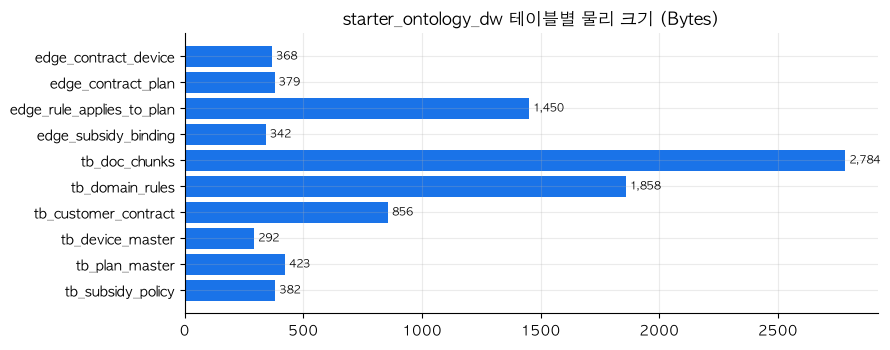

In [7]:
H.bar(df_tables, "table_id", "size_bytes", H.t("starter_ontology_dw 테이블별 물리 크기 (Bytes)", "Table Physical Size in Bytes"), horizontal=True)


### 3. [Phase 2b: 정형 원장 데이터 확인] 비식별 고객 약정(`CUST_DEMO_*`) · 단말 · 요금제 조인 및 180일 의무유지 경과일 분포 (`%%bqsql`)


In [8]:
%%bqsql df_contracts
SELECT c.customer_id, c.contract_id, c.customer_segment, c.age_group, c.welfare_status, c.contract_type,
       c.elapsed_days, c.granted_subsidy_krw, d.device_name, p.plan_name, p.monthly_fee_krw
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY c.customer_id


,customer_id,contract_id,customer_segment,age_group,welfare_status,contract_type,elapsed_days,granted_subsidy_krw,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,CONTRACT_DEMO_101,General_VIP,30s-40s,NONE,PUBLIC_SUBSIDY,120,517500,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,CONTRACT_DEMO_102,General_Standard,30s-40s,NONE,PUBLIC_SUBSIDY,224,575000,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,CONTRACT_DEMO_103,Senior_Welfare,65+,SENIOR_EXEMPT,PUBLIC_SUBSIDY,88,460000,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,CONTRACT_DEMO_104,General_Standard,30s-40s,NONE,SELECTIVE_25PCT,109,0,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,CONTRACT_DEMO_105,Youth_Family,20s,MILITARY_PAUSE_ELIGIBLE,PUBLIC_SUBSIDY,57,345000,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,CONTRACT_DEMO_106,Corporate_B2B,30s-40s,NONE,PUBLIC_SUBSIDY,170,345000,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


,customer_id,contract_id,customer_segment,age_group,welfare_status,contract_type,elapsed_days,granted_subsidy_krw,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,CONTRACT_DEMO_101,General_VIP,30s-40s,NONE,PUBLIC_SUBSIDY,120,517500,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,CONTRACT_DEMO_102,General_Standard,30s-40s,NONE,PUBLIC_SUBSIDY,224,575000,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,CONTRACT_DEMO_103,Senior_Welfare,65+,SENIOR_EXEMPT,PUBLIC_SUBSIDY,88,460000,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,CONTRACT_DEMO_104,General_Standard,30s-40s,NONE,SELECTIVE_25PCT,109,0,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,CONTRACT_DEMO_105,Youth_Family,20s,MILITARY_PAUSE_ELIGIBLE,PUBLIC_SUBSIDY,57,345000,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,CONTRACT_DEMO_106,Corporate_B2B,30s-40s,NONE,PUBLIC_SUBSIDY,170,345000,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


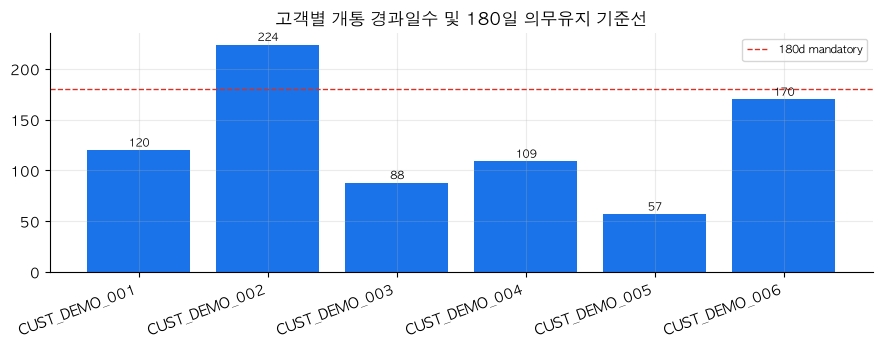

In [9]:
H.show(df_contracts)
H.bar(df_contracts, "customer_id", "elapsed_days",
      H.t("고객별 개통 경과일수 및 180일 의무유지 기준선", "Customer Elapsed Days vs. 180-Day Mandatory Retention Line"),
      hline=180, hline_label="180d mandatory")


### 4. [Phase 2c: 지원금 정책 데이터 탐색] 단말기 × 요금제별 공시/추가지원금 구조 및 실구매가 히트맵 (`%%bqsql`)


In [10]:
%%bqsql df_sub
SELECT s.policy_id, d.device_name, p.plan_name, p.monthly_fee_krw, d.factory_price_krw,
       s.base_subsidy_krw, s.additional_subsidy_cap_krw,
       s.base_subsidy_krw + s.additional_subsidy_cap_krw AS total_subsidy_krw,
       d.factory_price_krw - (s.base_subsidy_krw + s.additional_subsidy_cap_krw) AS net_price_krw,
       s.mandatory_retention_days
FROM `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY d.device_name, p.monthly_fee_krw DESC


,policy_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,base_subsidy_krw,additional_subsidy_cap_krw,total_subsidy_krw,net_price_krw,mandatory_retention_days
0,POL-2026-001,Galaxy S26 Ultra 256GB,5G Premier Super,130000,1698400,500000,75000,575000,1123400,180
1,POL-2026-002,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,450000,67500,517500,1180900,180
2,POL-2026-003,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000,1698400,300000,45000,345000,1353400,180
3,POL-2026-004,Galaxy S26 Ultra 256GB,5G Light (Below Baseline),37000,1698400,150000,22500,172500,1525900,180
4,POL-2026-005,iPhone 16 Pro 256GB,5G Premier Essential,85000,1700000,400000,60000,460000,1240000,180


,policy_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,base_subsidy_krw,additional_subsidy_cap_krw,total_subsidy_krw,net_price_krw
0,POL-2026-001,Galaxy S26 Ultra 256GB,5G Premier Super,130000,1698400,500000,75000,575000,1123400
1,POL-2026-002,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,450000,67500,517500,1180900
2,POL-2026-003,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000,1698400,300000,45000,345000,1353400
3,POL-2026-004,Galaxy S26 Ultra 256GB,5G Light (Below Baseline),37000,1698400,150000,22500,172500,1525900
4,POL-2026-005,iPhone 16 Pro 256GB,5G Premier Essential,85000,1700000,400000,60000,460000,1240000


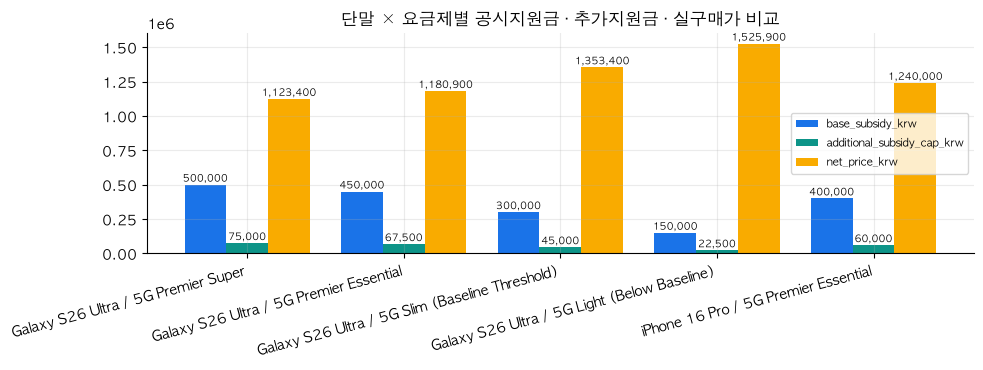

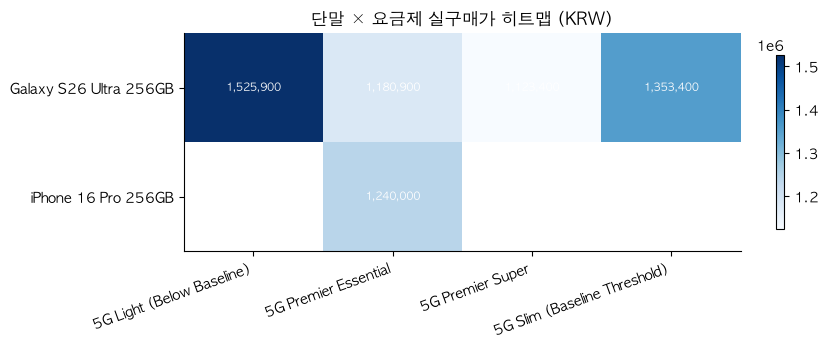

In [11]:
d_sub = H.pdf(df_sub)
d_sub["device_plan"] = d_sub["device_name"].str.replace(" 256GB", "") + " / " + d_sub["plan_name"]
H.show(d_sub[["policy_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "base_subsidy_krw", "additional_subsidy_cap_krw", "total_subsidy_krw", "net_price_krw"]])
H.grouped_bar(d_sub, "device_plan", ["base_subsidy_krw", "additional_subsidy_cap_krw", "net_price_krw"],
              H.t("단말 × 요금제별 공시지원금 · 추가지원금 · 실구매가 비교", "Base Subsidy, Additional Cap & Net Price by Device × Plan"))
H.heatmap(d_sub.pivot(index="device_name", columns="plan_name", values="net_price_krw"),
          H.t("단말 × 요금제 실구매가 히트맵 (KRW)", "Net Purchase Price Heatmap (KRW)"))


### 5. [Phase 2d: 비정형 문서 · 용어사전 · Golden CQ 설계] 정책 청크 용어 빈도(`%%bqsql`) 및 Golden CQ 5종 정답 SQL 대조 검증


In [12]:
%%bqsql df_terms
SELECT term, chunk_id, ARRAY_LENGTH(REGEXP_EXTRACT_ALL(content, term)) AS hits
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks`, UNNEST(['공시지원금', '유통망', '180일', '차액정산', '위약금', '선택약정', '복지']) AS term
ORDER BY term, chunk_id


,term,chunk_id,hits
0,180일,DOC_CHUNK_001,0
1,180일,DOC_CHUNK_002,0
2,180일,DOC_CHUNK_003,0
3,180일,DOC_CHUNK_004,0
4,180일,DOC_CHUNK_005,0
5,공시지원금,DOC_CHUNK_001,0
6,공시지원금,DOC_CHUNK_002,0
7,공시지원금,DOC_CHUNK_003,0
8,공시지원금,DOC_CHUNK_004,0
9,공시지원금,DOC_CHUNK_005,0


,term,definition
0,공시지원금,단말기 출고가에서 이동통신사가 최초 개통 시 1회 직접 차감해주는 법적 단말 구매 보조금
1,유통망지원금,유통 대리점에서 공시지원금의 최대 15% 한도 내에서 합법적으로 추가 지급하는 보조금
2,식스플랜 (180일 약정),공시지원금을 수령한 고객이 개통일로부터 180일 동안 특정 요금제선 이상을 유지해야 하는 의무 약정
3,차액정산금 (위약금),180일 이내에 기준 요금제선 미만으로 하향 변경 시 잔여 기간에 비례하여 부과되는 반환금


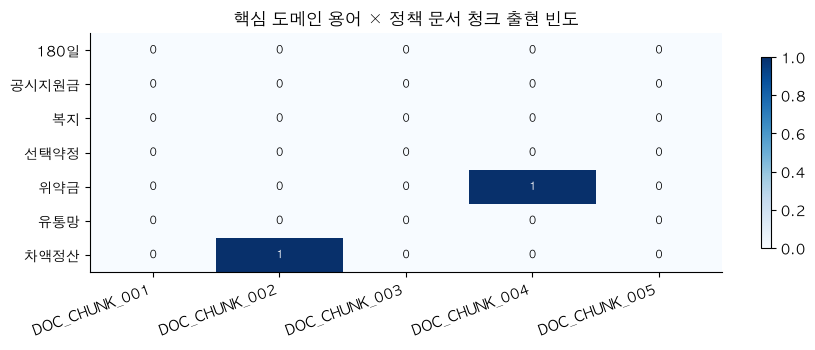

,cq_id,category,grounded_chunk,expected_math,bigquery_result,match,job_id
0,CQ-01,Single-Hop Lookup,DOC_CHUNK_001,{'factory_price': 1698400},{'factory_price': 1698400},True,job_zeLf1sNczhsPh7HdtJ5vRf6HEJ26
1,CQ-02,Two-Hop Subsidy,DOC_CHUNK_002,"{'subsidy': 517500, 'net_price': 1180900}","{'subsidy': 517500, 'net_price': 1180900}",True,job_x7cPEWOFLetJ60yAmeXTIAG_dDI3
2,CQ-03,Multi-Hop Penalty,DOC_CHUNK_003,{'penalty': 100000},{'penalty': 100000},True,job_E0bCwQxCk6KsGRZ_XhyNW2mhSRrj
3,CQ-04,24M TCO Optimization,DOC_CHUNK_005,"{'public_subsidy_total': 517500, 'selective_discount_total': 510000, 'tco_savings': 7500}","{'public_subsidy_total': 517500, 'selective_discount_total': 510000, 'tco_savings': 7500}",True,job_joTeLodN8GU4q_XwbpkRw3b0AYQf
4,CQ-05,Welfare Exemption & Lineage,DOC_CHUNK_004,"{'penalty': 0, 'exemption_rule': 'RULE_WELFARE_EXEMPT'}","{'penalty': 0, 'exemption_rule': 'RULE_WELFARE_EXEMPT'}",True,job_Edsvr4oXcbdc_LZy6tyKMoj4nWLx


,case_id,root_cause_code,missing_context,query,expected_behavior
0,BQ-01,NO_SLOT_FILLING,고객 ID / 현재 요금제 / 변경 희망 요금제 미지정,개통한 지 4개월 됐는데 요금제 낮추면 위약금 나오나요?,금액을 단정하지 않고 부족한 정보(고객 ID·변경 요금제 등)를 안내
1,BQ-02,MISSING_EXCEPTION_EDGE,시니어 특례 면제 등록 여부 미지정,어르신 요금제로 바꾸려는데 180일 안 지났으면 위약금 내야 하나요?,시니어 특례(RULE_WELFARE_EXEMPT / DOC_CHUNK_004) 조건을 안내하고 고객 정보를 요청
2,BQ-03,NO_SLOT_FILLING,용량(256GB/512GB) 및 가입 요금제 미지정,갤럭시 S26 울트라 지금 사면 지원금 얼마 받아요?,BigQuery 지원금 정책의 요금제별 총 지원금을 제시
3,BQ-04,MISSING_ENTITY,군입대 정지 특례 엔티티 참조,군대 입대 때문에 일시정지하면 180일 의무기간은 어떻게 되나요?,군입대 장기정지 특례(MILITARY_PAUSE_ELIGIBLE / DOC_CHUNK_004) 근거를 인용
4,BQ-05,NO_ALIAS_DICT,단말 별칭(아이폰 최신형 프로) 및 요금제 미지정,아이폰 최신형 프로 모델 선약이랑 공시 중 뭐가 더 이득인가요?,카탈로그의 iPhone 16 Pro로 매핑하고 BigQuery 정책 기준 24개월 총비용 차액을 제시
5,BQ-06,NO_SLOT_FILLING,180일 경과 후 면제 경계값,개통 185일째인데 제일 싼 LTE 요금제로 내려도 위약금 없죠?,경과일 185일이 의무기간 이상이므로 위약금 0원
6,BQ-07,MISSING_ENTITY,노드 테이블 중복 키 메타데이터 조회,지원금 테이블이랑 실제 그래프 노드에 중복 적재된 데이터가 있나요?,Stage 3 실측 결과(노드 테이블 중복 키 건수)를 제시
7,BQ-08,MISSING_EXCEPTION_EDGE,기준선 이상 요금제 간 하향 시 차액정산 여부,5G 프리미어 에센셜에서 다이렉트 61로 바꾸면 기준선 위반인가요?,변경 요금제 월정액이 기준선 이상이므로 기준선 위반 아님
8,BQ-09,MISSING_ENTITY,법인(Corporate_B2B) 세그먼트 정책 매핑,법인 명의로 개통한 회선도 180일 식스플랜 룰이 똑같이 적용되나요?,세그먼트별 예외 규칙 존재 여부를 도구 결과로 밝히고 RULE_SIX_PLAN_180D 근거를 인용
9,BQ-10,NO_ALIAS_DICT,BigQuery Graph vs Spanner Graph 호환성,Spanner Graph로 전환하면 지금 쓰는 GQL 쿼리랑 스키마를 다 새로 짜야 하나요?,도구 실측 결과(BigQuery Property Graph)에 근거해 답하고 결과에 없는 내용은 단정하지 않음


In [13]:
glossary = H.read_json("data/input/05_glossary/business_glossary.json")
H.show(pd.DataFrame([{"term": k, "definition": v} for k, v in glossary.items()] if isinstance(glossary, dict) else glossary))
H.heatmap(H.pdf(df_terms).pivot(index="term", columns="chunk_id", values="hits"),
          H.t("핵심 도메인 용어 × 정책 문서 청크 출현 빈도", "Domain Term × Policy Document Chunk Frequency"), fmt="{:.0f}")
cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
H.show(H.check_cq_sql(cqs))
bcs = H.read_json("data/input/04_cq/boundary_cases.json")
H.show(bcs, ["case_id", "root_cause_code", "missing_context", "query", "expected_behavior"])


### Q&A
- **Q.** 왜 온톨로지와 그래프를 만들기 전에 Golden CQ와 `verification_sql`을 먼저 정의하나요?
  - **A.** 에이전트가 답해야 할 질문과 결정론적 정답 산식(`expected_math`, `verification_sql`, `grounded_chunk`)을 Stage 1에서 먼저 확정해야 불필요한 테이블 적재를 막고(Scoping), Stage 5에서 에이전트 답변을 SQL 실측치와 1:1 자동 대조할 수 있기 때문입니다.

### Data Analysis Key Findings
- `starter_ontology_dw` 내 10개 테이블 스키마(`INFORMATION_SCHEMA.COLUMNS`)와 62개 행이 정상 적재되었으며, `CUST_DEMO_001~006` 비식별 규칙 위반 건수는 `0건`입니다.
- 6명의 고객 약정 중 5건(`elapsed_days`: 45~120일)이 180일 의무유지 기간 이내에 있어 요금제 하향 시 일할 차액정산 또는 복지 면제 규칙 판정이 필요합니다.
- Golden CQ 5종(`CQ-01`~`CQ-05`)의 `verification_sql`을 BigQuery에서 직접 실행한 결과, `expected_math`와 5건 모두 일치(`match=True`)함을 확인했습니다.

### Insights or Next Steps
- 다음 단계인 `Stage 2 (파싱·통합)` 노트북으로 이동하여 비정형 정책 가이드 마크다운을 SHA-256 해시 앵커 청크로 파싱하고, Karpathy 3-Layer LLM-Wiki 및 시맨틱 온톨로지 그래프로 통합하는 과정을 확인하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ 0. 전체 흐름 개요](./stage0_overview_walkthrough.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough.ipynb) ｜ [➡️ Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) ｜ [🌐 English Version](./stage1_asset_and_cq_en.ipynb) ｜ [📖 방법론 문서](../methodology/01_stage1_asset_and_cq_ko.md)
